In [ ]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

uploaded = files.upload()
df = pd.read_csv('energydata_complete.csv')

df = df.rename(columns={
    'date': 'Ngày giờ',
    'Appliances': 'Điện thiết bị (Wh)',
    'lights': 'Điện đèn (Wh)',
    'T1': 'Nhiệt độ bếp', 'RH_1': 'Độ ẩm bếp',
    'T2': 'Nhiệt độ phòng khách', 'RH_2': 'Độ ẩm phòng khách',
    'T3': 'Nhiệt độ phòng giặt', 'RH_3': 'Độ ẩm phòng giặt',
    'T4': 'Nhiệt độ phòng làm việc', 'RH_4': 'Độ ẩm phòng làm việc',
    'T5': 'Nhiệt độ phòng tắm', 'RH_5': 'Độ ẩm phòng tắm',
    'T6': 'Nhiệt độ ngoài nhà', 'RH_6': 'Độ ẩm ngoài nhà',
    'T7': 'Nhiệt độ phòng ủi đồ', 'RH_7': 'Độ ẩm phòng ủi đồ',
    'T8': 'Nhiệt độ phòng thiếu niên', 'RH_8': 'Độ ẩm phòng thiếu niên',
    'T9': 'Nhiệt độ phòng ba mẹ', 'RH_9': 'Độ ẩm phòng ba mẹ',
    'T_out': 'Nhiệt độ ngoài trời',
    'Press_mm_hg': 'Áp suất (mmHg)',
    'RH_out': 'Độ ẩm ngoài trời',
    'Windspeed': 'Tốc độ gió',
    'Visibility': 'Tầm nhìn',
    'Tdewpoint': 'Điểm sương',
    'rv1': 'Biến ngẫu nhiên 1',
    'rv2': 'Biến ngẫu nhiên 2',
})

df['Ngày giờ'] = pd.to_datetime(df['Ngày giờ'])
df['Tháng'] = df['Ngày giờ'].dt.month
df['Giờ'] = df['Ngày giờ'].dt.hour

df.head()

Saving energydata_complete.csv to energydata_complete (1).csv


,Ngày giờ,Điện thiết bị (Wh),Điện đèn (Wh),Nhiệt độ bếp,Độ ẩm bếp,Nhiệt độ phòng khách,Độ ẩm phòng khách,Nhiệt độ phòng giặt,Độ ẩm phòng giặt,Nhiệt độ phòng làm việc,...,Nhiệt độ ngoài trời,Áp suất (mmHg),Độ ẩm ngoài trời,Tốc độ gió,Tầm nhìn,Điểm sương,Biến ngẫu nhiên 1,Biến ngẫu nhiên 2,Tháng,Giờ
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,1,17
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,1,17
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,1,17
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,1,17
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,1,17


In [ ]:
ten_thang = {1:'Tháng 1', 2:'Tháng 2', 3:'Tháng 3', 4:'Tháng 4', 5:'Tháng 5'}

bang = df.groupby('Tháng').agg(**{
    'Số lần đo': ('Điện thiết bị (Wh)', 'count'),
    'Tổng điện thiết bị (Wh)': ('Điện thiết bị (Wh)', 'sum'),
    'TB điện thiết bị (Wh)': ('Điện thiết bị (Wh)', 'mean'),
    'Cao nhất (Wh)': ('Điện thiết bị (Wh)', 'max'),
    'Tổng điện đèn (Wh)': ('Điện đèn (Wh)', 'sum'),
    'TB nhiệt độ bếp (°C)': ('Nhiệt độ bếp', 'mean'),
    'TB độ ẩm bếp (%)': ('Độ ẩm bếp', 'mean'),
    'TB nhiệt độ ngoài trời (°C)': ('Nhiệt độ ngoài trời', 'mean'),
    'TB độ ẩm ngoài trời (%)': ('Độ ẩm ngoài trời', 'mean'),
    'TB tốc độ gió (m/s)': ('Tốc độ gió', 'mean'),
}).round(2)

bang.index = bang.index.map(ten_thang)
bang.index.name = 'Tháng'
bang['Tổng điện (kWh)'] = ((bang['Tổng điện thiết bị (Wh)'] + bang['Tổng điện đèn (Wh)']) / 1000).round(2)
bang

,Số lần đo,Tổng điện thiết bị (Wh),TB điện thiết bị (Wh),Cao nhất (Wh),Tổng điện đèn (Wh),TB nhiệt độ bếp (°C),TB độ ẩm bếp (%),TB nhiệt độ ngoài trời (°C),TB độ ẩm ngoài trời (%),TB tốc độ gió (m/s),Tổng điện (kWh)
Tháng,,,,,,,,,,,
Tháng 1,2922,283510,97.03,1080,13800,19.95,42.28,4.13,86.61,4.80,297.31
Tháng 2,4176,421550,100.95,770,26490,21.16,41.01,4.82,84.23,4.85,448.04
Tháng 3,4464,432800,96.95,880,17480,21.26,37.92,5.44,80.73,3.99,450.28
Tháng 4,4320,427200,98.89,900,10440,21.86,39.72,8.51,77.21,3.65,437.64
Tháng 5,3853,362950,94.20,850,6820,23.88,41.22,13.76,71.40,3.08,369.77


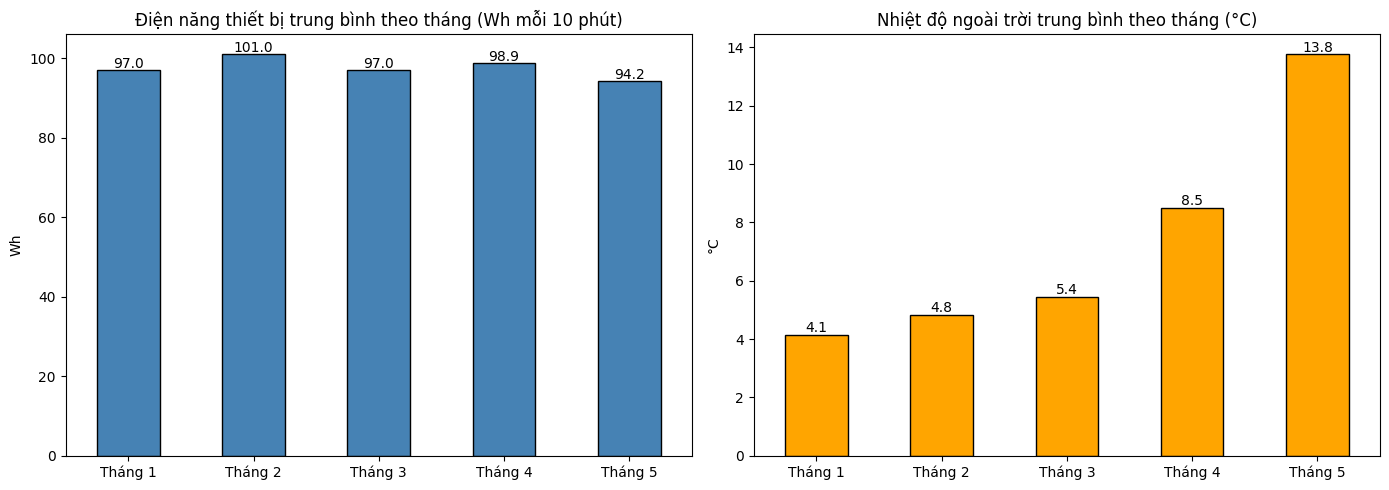

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

bang['TB điện thiết bị (Wh)'].plot(kind='bar', ax=ax[0], color='steelblue', edgecolor='black')
ax[0].set_title('Điện năng thiết bị trung bình theo tháng (Wh mỗi 10 phút)')
ax[0].set_ylabel('Wh')
ax[0].set_xlabel('')
ax[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(bang['TB điện thiết bị (Wh)']):
    ax[0].text(i, v + 0.5, f'{v:.1f}', ha='center')

bang['TB nhiệt độ ngoài trời (°C)'].plot(kind='bar', ax=ax[1], color='orange', edgecolor='black')
ax[1].set_title('Nhiệt độ ngoài trời trung bình theo tháng (°C)')
ax[1].set_ylabel('°C')
ax[1].set_xlabel('')
ax[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(bang['TB nhiệt độ ngoài trời (°C)']):
    ax[1].text(i, v + 0.1, f'{v:.1f}', ha='center')

plt.tight_layout()
plt.show()

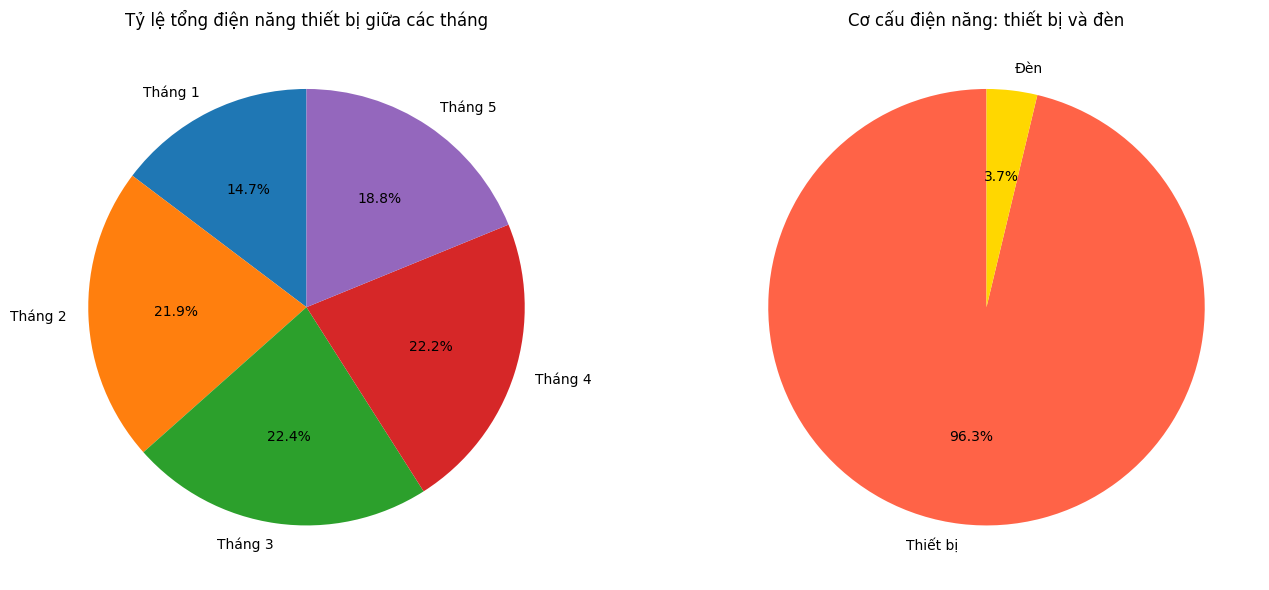

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].pie(bang['Tổng điện thiết bị (Wh)'], labels=bang.index,
          autopct='%1.1f%%', startangle=90)
ax[0].set_title('Tỷ lệ tổng điện năng thiết bị giữa các tháng')

tong = [df['Điện thiết bị (Wh)'].sum(), df['Điện đèn (Wh)'].sum()]
ax[1].pie(tong, labels=['Thiết bị', 'Đèn'],
          autopct='%1.1f%%', startangle=90, colors=['tomato', 'gold'])
ax[1].set_title('Cơ cấu điện năng: thiết bị và đèn')

plt.tight_layout()
plt.show()

Giờ                          0.217
Điện đèn (Wh)                0.197
Độ ẩm ngoài trời            -0.152
Nhiệt độ phòng khách         0.120
Nhiệt độ ngoài nhà           0.118
Nhiệt độ ngoài trời          0.099
Độ ẩm phòng thiếu niên      -0.094
Tốc độ gió                   0.087
Độ ẩm bếp                    0.086
Nhiệt độ phòng giặt          0.085
Độ ẩm ngoài nhà             -0.083
Độ ẩm phòng khách           -0.060
Độ ẩm phòng ủi đồ           -0.056
Nhiệt độ bếp                 0.055
Độ ẩm phòng ba mẹ           -0.051
Nhiệt độ phòng làm việc      0.040
Nhiệt độ phòng thiếu niên    0.040
Độ ẩm phòng giặt             0.036
Áp suất (mmHg)              -0.035
Nhiệt độ phòng ủi đồ         0.026
Nhiệt độ phòng tắm           0.020
Độ ẩm phòng làm việc         0.017
Điểm sương                   0.015
Nhiệt độ phòng ba mẹ         0.010
Độ ẩm phòng tắm              0.007
Tầm nhìn                     0.000
Name: Điện thiết bị (Wh), dtype: float64


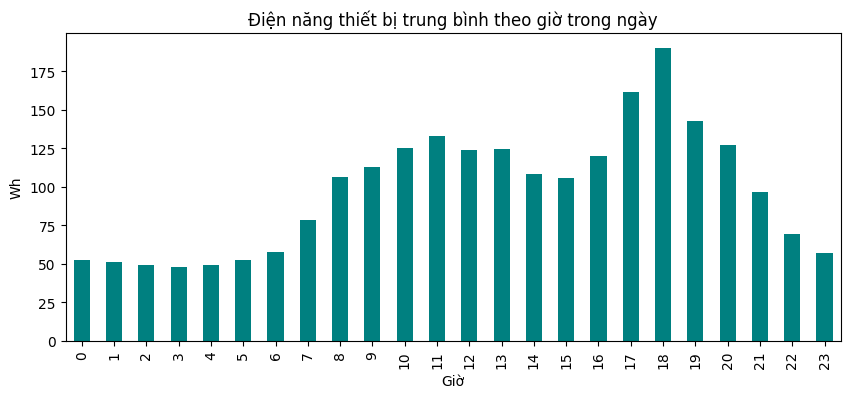

In [ ]:
bo_qua = ['Ngày giờ', 'Tháng', 'Biến ngẫu nhiên 1', 'Biến ngẫu nhiên 2', 'Điện thiết bị (Wh)']
cot_can = [c for c in df.columns if c not in bo_qua]

tuong_quan = df[cot_can + ['Điện thiết bị (Wh)']].corr()['Điện thiết bị (Wh)'].drop('Điện thiết bị (Wh)')
print(tuong_quan.sort_values(key=abs, ascending=False).round(3))

df.groupby('Giờ')['Điện thiết bị (Wh)'].mean().plot(kind='bar', figsize=(10,4), color='teal')
plt.title('Điện năng thiết bị trung bình theo giờ trong ngày')
plt.xlabel('Giờ')
plt.ylabel('Wh')
plt.show()